# Tarea 5. Implementación de un Perceptrón en Python

**Asignatura:** Inteligencia Artificial  
**Docente:** José Mario Ríos Félix  
**Horario:** 6:00 - 7:00 p. m.  
**Estudiante:** Rodrigo Villegas Valdez  
**No. de control:** 23170371

En esta práctica se entrena un modelo de perceptrón utilizando `scikit-learn` para clasificar dos conjuntos de datos linealmente separables. Además, se analizan distintas funciones de activación y se desarrolla el caso práctico de una neurona lineal visto en clase.

## 1. Fundamentos del Perceptrón

El perceptrón representa la unidad básica de una red neuronal artificial y se emplea principalmente para problemas de clasificación binaria. Su operación se resume en tres pasos:

1. **Ponderación:** Cada valor de entrada se multiplica por un peso ($w$) asignado.
2. **Suma neta:** Se suman todos los productos anteriores y se añade un término independiente llamado sesgo o *bias* ($b$).
3. **Activación:** Se evalúa el resultado mediante una función escalón; si el valor es mayor o igual a cero, la neurona se activa (clase 1), de lo contrario permanece inactiva (clase 0).

El aprendizaje ocurre de forma iterativa a lo largo de varias pasadas sobre el conjunto de datos (épocas), ajustando los pesos y el sesgo cada vez que la predicción no coincide con la etiqueta real.

*Documentación oficial:* https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.linear_model import Perceptron

# Generación de 120 muestras distribuidas en 2 grupos linealmente separables
X, Y = make_blobs(n_samples=120, centers=2, n_features=2, cluster_std=1.15, random_state=77)

print(f"Total de muestras generadas: {len(X)}")
print(f"Dimensión de características: {X.shape[1]}")
print(f"Distribución -> Grupo 0: {np.sum(Y == 0)} | Grupo 1: {np.sum(Y == 1)}")

Total de muestras generadas: 120
Dimensión de características: 2
Distribución -> Grupo 0: 60 | Grupo 1: 60


In [8]:
# Inicialización y entrenamiento del modelo
modelo_perceptron = Perceptron(tol=1e-3, random_state=42)
modelo_perceptron.fit(X, Y)

# Extracción de parámetros aprendidos (pesos y sesgo)
w1, w2 = modelo_perceptron.coef_[0]
b = modelo_perceptron.intercept_[0]

print(f"Peso w1: {w1:.4f}")
print(f"Peso w2: {w2:.4f}")
print(f"Sesgo b: {b:.4f}")
print(f"Iteraciones (épocas) hasta converger: {modelo_perceptron.n_iter_}")
print(f"Precisión en entrenamiento: {modelo_perceptron.score(X, Y):.2%}")

Peso w1: -3.4371
Peso w2: -11.6842
Sesgo b: 0.0000
Iteraciones (épocas) hasta converger: 7
Precisión en entrenamiento: 100.00%


In [9]:
# Verificación matemática manual de la regla de decisión
z = np.dot(X, modelo_perceptron.coef_[0]) + b  # Producto punto + sesgo
prediccion_manual = np.where(z >= 0, 1, 0)     # Función escalón unitario

print(f"Valor de z (últimas 6 muestras): {np.round(z[-6:], 2)}")
print(f"Predicción manual:               {prediccion_manual[-6:]}")
print(f"Etiqueta esperada:               {Y[-6:]}")
print(f"¿Coincide con .predict()?:       {np.array_equal(prediccion_manual, modelo_perceptron.predict(X))}")

Valor de z (últimas 6 muestras): [ 59.88  64.27 -46.71 -46.9   58.23  62.78]
Predicción manual:               [1 1 0 0 1 1]
Etiqueta esperada:               [1 1 0 0 1 1]
¿Coincide con .predict()?:       True


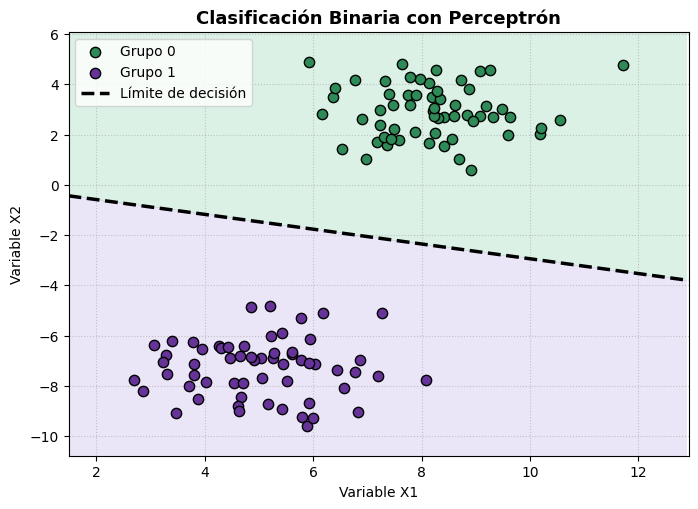

In [10]:
plt.figure(figsize=(8, 5.5))

# Creación de malla para colorear las regiones de clasificación
x_min, x_max = X[:, 0].min() - 1.2, X[:, 0].max() + 1.2
y_min, y_max = X[:, 1].min() - 1.2, X[:, 1].max() + 1.2
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))

regiones = modelo_perceptron.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.contourf(xx, yy, regiones, levels=[-0.5, 0.5, 1.5], colors=['mediumseagreen', 'mediumpurple'], alpha=0.18)

# Graficación de los puntos por clase
plt.scatter(X[Y == 0][:, 0], X[Y == 0][:, 1], color='seagreen', edgecolor='k', s=55, label='Grupo 0', zorder=5)
plt.scatter(X[Y == 1][:, 0], X[Y == 1][:, 1], color='rebeccapurple', edgecolor='k', s=55, label='Grupo 1', zorder=5)

# Trazo de la recta separadora: w1*x1 + w2*x2 + b = 0  =>  x2 = -(w1*x1 + b) / w2
x_vals = np.linspace(x_min, x_max, 100)
y_vals = -(w1 * x_vals + b) / w2
plt.plot(x_vals, y_vals, color='black', linestyle='--', linewidth=2.5, label='Límite de decisión', zorder=4)

plt.title('Clasificación Binaria con Perceptrón', fontsize=13, fontweight='bold')
plt.xlabel('Variable X1')
plt.ylabel('Variable X2')
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

### Análisis de los resultados obtenidos

Al finalizar el entrenamiento tras **7 épocas**, el modelo ajustó la recta separadora con los parámetros $w_1 = -3.4371$, $w_2 = -11.6842$ y $b = 0.0000$, quedando definida por la ecuación $-3.4371 x_1 - 11.6842 x_2 = 0$. Esta frontera divide el plano en dos regiones: los puntos ubicados por debajo de la línea se clasifican en el Grupo 0 y los que quedan por encima en el Grupo 1.

El algoritmo alcanzó una precisión del **100.00%** debido a que los clústeres generados son linealmente separables (sin traslape entre clases). Si los datos presentaran ruido o una distribución no lineal, un perceptrón simple no lograría converger a una separación perfecta. Asimismo, se verificó que el cálculo matricial manual con la función escalón coincide exactamente con las predicciones generadas por `.predict()`.

## 2. Comparativa de Funciones de Activación

Las funciones de activación introducen no linealidad en las redes neuronales, determinando si una neurona debe activarse o no a partir de su suma ponderada ($z$).

| Función | Rango de salida | Característica principal |
|---|---|---|
| **Escalón (Step)** | $\{0, 1\}$ | Umbral binario rígido; base del perceptrón clásico. |
| **Sigmoide** | $(0, 1)$ | Curva suave en forma de "S"; útil para estimar probabilidades. |
| **Tangente Hiperbólica (Tanh)** | $(-1, 1)$ | Centrada en cero; suele converger mejor que la sigmoide en capas ocultas. |
| **ReLU** | $[0, \infty)$ | Mantiene valores positivos y anula los negativos; estándar en *Deep Learning*. |

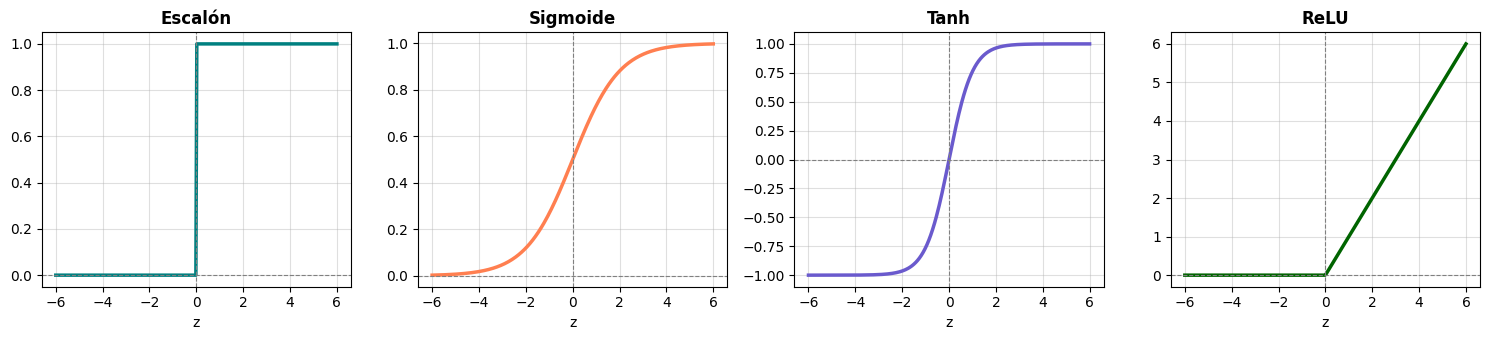

In [11]:
z_vals = np.linspace(-6, 6, 300)

# Definición de funciones
escalon = np.where(z_vals >= 0, 1, 0)
sigmoide = 1 / (1 + np.exp(-z_vals))
tanh = np.tanh(z_vals)
relu = np.maximum(0, z_vals)

fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))

funciones = [
    (escalon, 'Escalón', 'teal'),
    (sigmoide, 'Sigmoide', 'coral'),
    (tanh, 'Tanh', 'slateblue'),
    (relu, 'ReLU', 'darkgreen')
]

for ax, (func, nombre, color) in zip(axs, funciones):
    ax.plot(z_vals, func, color=color, linewidth=2.5)
    ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
    ax.axvline(0, color='gray', linewidth=0.8, linestyle='--')
    ax.set_title(nombre, fontweight='bold')
    ax.set_xlabel('z')
    ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

## 3. Ejemplo de Neurona Lineal (Regresión)

A diferencia del perceptrón que clasifica usando una función escalón, una **neurona lineal** utiliza una función de activación identidad ($f(z) = z$). Esto permite predecir valores numéricos continuos (regresión lineal), como aproximar una relación directa entre una entrada $x$ y una salida $y$.

Ecuación aprendida: y = 3.64x + 2.72


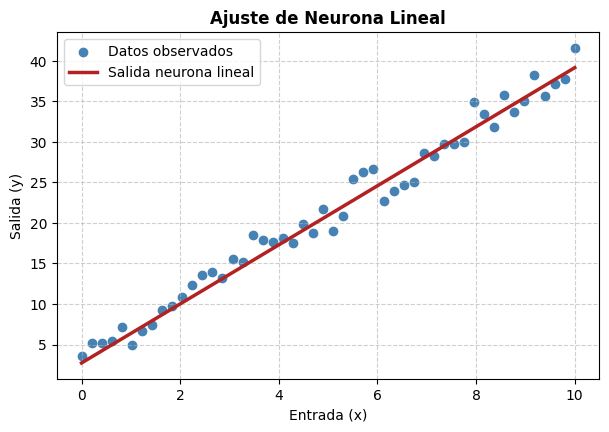

In [12]:
from sklearn.linear_model import SGDRegressor

# Datos sintéticos con tendencia lineal + ligero ruido (ej. y = 3.5x + 4)
np.random.seed(15)
X_lin = np.linspace(0, 10, 50).reshape(-1, 1)
Y_lin = 3.5 * X_lin.ravel() + 4 + np.random.normal(0, 1.5, size=50)

# Entrenamiento de neurona lineal mediante descenso de gradiente
neurona_lineal = SGDRegressor(max_iter=1000, tol=1e-3, random_state=15)
neurona_lineal.fit(X_lin, Y_lin)

w_lin = neurona_lineal.coef_[0]
b_lin = neurona_lineal.intercept_[0]

print(f"Ecuación aprendida: y = {w_lin:.2f}x + {b_lin:.2f}")

# Gráfica del ajuste lineal
plt.figure(figsize=(7, 4.5))
plt.scatter(X_lin, Y_lin, color='steelblue', label='Datos observados')
plt.plot(X_lin, neurona_lineal.predict(X_lin), color='firebrick', linewidth=2.5, label='Salida neurona lineal')
plt.title('Ajuste de Neurona Lineal', fontweight='bold')
plt.xlabel('Entrada (x)')
plt.ylabel('Salida (y)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()